# HC-AAL v2: Five-model heterogeneous committee

**Dataset:** Kaggle `johnsmith88/heart-disease-dataset` (`heart.csv`).

This notebook adapts the paper's HC-AAL method to a five-classifier committee:
**XGBoost, SVM (RBF), Random Forest, Logistic Regression, and CatBoost.**

It retains:
1. Committee-weighted uncertainty (CW-QBC)
2. K-Means diversity selection from the top uncertain candidates
3. Adaptive query sizes cycling through 3, 4, and 5
4. Iterative simulated oracle labelling and committee retraining

**Method notes**
- CW-QBC uses the paper-inspired positive-class score: sum over models of `p_m(x) * log((p_m(x)+eps)/(mean_p(x)+eps))`.
- SVM and Logistic Regression are scaled; tree models use numeric features directly.
- Queried labels are revealed only from the training pool. The test set is held out throughout.
- The paper's 31.9% labelled-data target is used as a fraction of the training partition.
- A small-dataset safeguard increases the initial labelled set to at least 10 records and ensures class representation. This is an explicit practical adaptation.
- This is a research implementation, not a clinical diagnostic tool.


## 1. Kaggle environment setup

This notebook is designed for Kaggle. It uses Kaggle's preinstalled NumPy, Pandas, SciPy, Matplotlib and scikit-learn. Do not upgrade these core packages here.

In [1]:
# Check only the additional model dependency. Do not upgrade Kaggle's core scientific stack.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("catboost") is None:
    print("CatBoost is missing; installing CatBoost without changing other dependencies.")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", "--no-deps", "catboost"
    ])
else:
    print("CatBoost is already installed.")

print("Using Kaggle-managed NumPy/Pandas/SciPy/Matplotlib/scikit-learn versions.")

CatBoost is already installed.
Using Kaggle-managed NumPy/Pandas/SciPy/Matplotlib/scikit-learn versions.


In [2]:
import os, json, time, warnings, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
N_RUNS = 10
TEST_SIZE = 0.20
INITIAL_LABEL_FRACTION = 0.015
LABEL_BUDGET_FRACTION = 0.319
QUERY_SIZES = [3, 4, 5]
EPS = 1e-12
ARTIFACT_DIR = Path('/kaggle/working/hcaal_v2_artifacts') if Path('/kaggle/working').exists() else Path('hcaal_v2_artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)
METRIC_NAMES = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


## 2. Load the exact Kaggle dataset you supplied

Dataset: [johnsmith88/heart-disease-dataset](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset)

In Kaggle:
1. Open the notebook.
2. Click **Add Input** on the right.
3. Search for **Heart Disease Dataset** by `johnsmith88` and add it.
4. Run the next cell.

The expected file is usually `/kaggle/input/heart-disease-dataset/heart.csv`. The loader checks that path first, then searches the attached Kaggle inputs for `heart.csv`.

In [3]:
from pathlib import Path
import pandas as pd

# Expected path for the Kaggle dataset slug supplied by you.
expected_path = Path("/kaggle/input/heart-disease-dataset/heart.csv")

if expected_path.exists():
    DATA_PATH = expected_path
else:
    # Fallback in case Kaggle mounts the dataset folder under a slightly different name.
    matches = list(Path("/kaggle/input").rglob("heart.csv"))
    if len(matches) == 1:
        DATA_PATH = matches[0]
    elif len(matches) > 1:
        print("Multiple heart.csv files found:")
        for i, path in enumerate(matches):
            print(i, path)
        raise ValueError(
            "More than one heart.csv was found. Set DATA_PATH manually to the "
            "johnsmith88 dataset path and rerun this cell."
        )
    else:
        raise FileNotFoundError(
            "heart.csv was not found. In Kaggle, click Add Input and attach "
            "johnsmith88/heart-disease-dataset."
        )

raw_df = pd.read_csv(DATA_PATH)
print("Loaded dataset:", DATA_PATH)
print("Dataset shape:", raw_df.shape)
print("Columns:", raw_df.columns.tolist())
display(raw_df.head())

# The supplied Kaggle version is commonly distributed as 1,025 rows x 14 columns.
if raw_df.shape != (1025, 14):
    print(
        "WARNING: Expected 1,025 rows and 14 columns for the commonly used "
        "johnsmith88 Kaggle CSV. Verify that the correct dataset version is attached."
    )

Loaded dataset: /kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv
Dataset shape: (1025, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 3. Validate the loaded dataset

## 4. Five-model committee

In [4]:
def build_committee(seed=42):
    return {
        'XGBoost': XGBClassifier(
            n_estimators=250, max_depth=3, learning_rate=0.04,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
            objective='binary:logistic', eval_metric='logloss',
            random_state=seed, n_jobs=-1, verbosity=0
        ),
        'SVM_RBF': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVC(C=1.0, kernel='rbf', probability=True,
                          class_weight='balanced', random_state=seed))
        ]),
        'Random_Forest': RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight='balanced',
            random_state=seed, n_jobs=-1
        ),
        'Logistic_Regression': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=3000, class_weight='balanced',
                                         random_state=seed))
        ]),
        'CatBoost': CatBoostClassifier(
            iterations=250, depth=4, learning_rate=0.04,
            loss_function='Logloss', verbose=False, random_seed=seed,
            allow_writing_files=False
        )
    }

def fit_committee(X, y, seed=42):
    committee = build_committee(seed)
    for model in committee.values():
        model.fit(X, y)
    return committee

def committee_probabilities(committee, X):
    return np.asarray([
        np.clip(model.predict_proba(X)[:, 1], EPS, 1-EPS)
        for model in committee.values()
    ])

def cwqbc_scores(committee, X_unlabelled):
    probs = committee_probabilities(committee, X_unlabelled)
    mean_p = probs.mean(axis=0)
    scores = np.sum(probs * np.log((probs + EPS) / (mean_p[None, :] + EPS)), axis=0)
    return scores, probs


## 5. CW-QBC uncertainty score

In [5]:
def cwqbc_scores(committee, X_unlabelled):
    probs = committee_probabilities(committee, X_unlabelled)
    mean_p = probs.mean(axis=0)
    score = np.sum(probs*np.log((probs+EPS)/(mean_p[None,:]+EPS)), axis=0)
    return score, probs

## 6. Adaptive query size and K-Means diversity

In [6]:
def choose_adaptive_q(iteration):
    return QUERY_SIZES[iteration % len(QUERY_SIZES)]

def select_diverse_uncertain(X_unlabelled, scores, q, feature_scaler, seed=42):
    n = len(X_unlabelled)
    if n == 0:
        return np.array([], dtype=int)
    q = min(int(q), n)
    candidate_ids = np.argsort(scores)[::-1][:min(n, 2*q)]
    candidates = X_unlabelled[candidate_ids]
    candidates_scaled = feature_scaler.transform(candidates)

    if q == 1:
        return candidate_ids[:1]

    km = KMeans(n_clusters=q, random_state=seed, n_init=10)
    labels = km.fit_predict(candidates_scaled)
    chosen = []
    for cluster in range(q):
        members = np.where(labels == cluster)[0]
        if len(members):
            distances = np.linalg.norm(
                candidates_scaled[members] - km.cluster_centers_[cluster], axis=1
            )
            chosen.append(members[np.argmin(distances)])

    chosen = list(dict.fromkeys(chosen))
    if len(chosen) < q:
        order = np.argsort(scores[candidate_ids])[::-1]
        for idx in order:
            if idx not in chosen:
                chosen.append(int(idx))
            if len(chosen) == q:
                break
    return candidate_ids[np.asarray(chosen[:q], dtype=int)]


## 7. Active-learning loop and evaluation

In [7]:
def stratified_initial_indices(y, fraction, seed):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    classes = np.unique(y)
    n0 = min(len(y), max(int(np.ceil(len(y)*fraction)), 2*len(classes), 10))
    selected = []
    for cls in classes:
        ids = np.where(y == cls)[0]
        take = min(len(ids), max(2, int(round(n0*len(ids)/len(y)))))
        selected.extend(rng.choice(ids, size=take, replace=False).tolist())
    selected = list(dict.fromkeys(selected))
    if len(selected) < n0:
        remaining = np.setdiff1d(np.arange(len(y)), selected)
        selected.extend(rng.choice(remaining, size=min(n0-len(selected), len(remaining)),
                                   replace=False).tolist())
    return np.asarray(selected, dtype=int)

def evaluate_committee(committee, X_test, y_test):
    p = committee_probabilities(committee, X_test).mean(axis=0)
    pred = (p >= 0.5).astype(int)
    result = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_test, p) if len(np.unique(y_test)) == 2 else np.nan
    }
    return result, p, pred

def run_hcaal_once(X_train, y_train, X_test, y_test, seed=42):
    X_train, X_test = np.asarray(X_train, float), np.asarray(X_test, float)
    y_train, y_test = np.asarray(y_train, int), np.asarray(y_test, int)
    initial = stratified_initial_indices(y_train, INITIAL_LABEL_FRACTION, seed)
    labelled = set(initial.tolist())
    pool = set(range(len(y_train)))
    budget = min(len(y_train), max(len(labelled),
                 int(np.ceil(len(y_train)*LABEL_BUDGET_FRACTION))))
    diversity_scaler = StandardScaler().fit(X_train)
    records, iteration = [], 0
    final_committee = None

    while True:
        labelled_ids = np.asarray(sorted(labelled), dtype=int)
        unlabelled_ids = np.asarray(sorted(pool-labelled), dtype=int)
        committee = fit_committee(X_train[labelled_ids], y_train[labelled_ids],
                                  seed + iteration)
        scores_test, p_test, pred_test = evaluate_committee(committee, X_test, y_test)
        scores_test.update({
            'iteration': iteration,
            'labelled_count': len(labelled_ids),
            'labelled_fraction': len(labelled_ids)/len(X_train)
        })
        records.append(scores_test)
        final_committee = committee

        if len(labelled) >= budget or len(unlabelled_ids) == 0:
            break

        q = choose_adaptive_q(iteration)
        scores, _ = cwqbc_scores(committee, X_train[unlabelled_ids])
        chosen_local = select_diverse_uncertain(
            X_train[unlabelled_ids], scores, q, diversity_scaler, seed+iteration
        )
        chosen_global = unlabelled_ids[chosen_local]
        if len(chosen_global) == 0:
            break
        labelled.update(chosen_global.tolist())
        iteration += 1

    return {'history': pd.DataFrame(records), 'models': final_committee,
            'labelled_indices': np.asarray(sorted(labelled)), 'budget': budget}

def run_repeated_experiment(X, y, seeds=range(N_RUNS)):
    seeds = list(seeds)
    all_histories, outputs = [], []
    for run_no, seed in enumerate(seeds, start=1):
        Xtr, Xte, ytr, yte = train_test_split(
            X, y, test_size=TEST_SIZE, random_state=int(seed), stratify=y
        )
        start = time.time()
        out = run_hcaal_once(Xtr, ytr, Xte, yte, int(seed))
        elapsed = time.time()-start
        h = out['history'].copy()
        h['run'], h['seed'], h['runtime_seconds'] = run_no, int(seed), elapsed
        all_histories.append(h)
        outputs.append({'run':run_no, 'seed':int(seed), 'runtime_seconds':elapsed,
                        'history':h, 'output':out, 'X_train':Xtr, 'X_test':Xte,
                        'y_train':ytr, 'y_test':yte})
        last = h.iloc[-1]
        print(f"Run {run_no}/{len(seeds)} | labels={int(last.labelled_count)} | "
              f"accuracy={last.accuracy:.3f} | AUC={last.roc_auc:.3f} | {elapsed:.1f}s")
    return pd.concat(all_histories, ignore_index=True), outputs


## 8. Dataset validation helper

In [8]:
def clean_binary_dataset(df, target_col, positive_values=None, drop_columns=None):
    data = df.copy()
    data.columns = [str(c).strip() for c in data.columns]
    if target_col not in data.columns:
        raise KeyError(f'Target {target_col!r} not found. Columns: {list(data.columns)}')
    if drop_columns:
        data = data.drop(columns=[c for c in drop_columns if c in data.columns and c != target_col])
    raw_y = data.pop(target_col)
    if positive_values is not None:
        y = raw_y.isin(positive_values).astype(int)
    else:
        values = set(pd.Series(raw_y).dropna().unique())
        if values.issubset({0,1}):
            y = raw_y.astype(int)
        elif values.issubset({1,2}):
            y = (raw_y.astype(int)==2).astype(int)
        else:
            raise ValueError(f'Explicitly map target values {values} to 0/1.')
    X = data.apply(pd.to_numeric, errors='coerce')
    if X.isna().any().any():
        raise ValueError('Missing/non-numeric predictor values found. Add imputation explicitly.')
    return X.astype(float), y.astype(int)

def show_dataset_summary(X, y):
    print('Shape:', X.shape)
    print('Target distribution (0=negative/absence, 1=positive/presence):')
    display(y.value_counts().sort_index().to_frame('count'))
    display(X.head())


## 8A. Map the paper dataset target

In [9]:
# This Kaggle CSV uses 'target' as its binary label:
# 0 = no heart disease, 1 = heart disease.
TARGET_COL = "target"
POSITIVE_VALUES = None  # Numeric 0/1 target is retained as-is.
DROP_COLUMNS = []

X, y = clean_binary_dataset(
    raw_df,
    target_col=TARGET_COL,
    positive_values=POSITIVE_VALUES,
    drop_columns=DROP_COLUMNS
)

print("Predictor columns:", list(X.columns))
print("Target mapping: 0 = absence, 1 = presence")

if X.shape[1] != 13:
    raise ValueError(
        f"Expected 13 predictor columns after removing target; found {X.shape[1]}. "
        "Check that the attached CSV is the intended Kaggle dataset."
    )
if len(raw_df) != 1025:
    print("WARNING: Dataset row count differs from the commonly reported 1,025 rows.")

# Duplicate audit. Keep rows unchanged for the main reproduction, but be aware that
# duplicates can leak across a random train/test split and inflate test metrics.
full_duplicates = int(raw_df.duplicated().sum())
feature_duplicates = int(X.duplicated().sum())
print(f"Exact duplicate full rows: {full_duplicates}")
print(f"Duplicate predictor rows (ignoring target): {feature_duplicates}")
if full_duplicates:
    print(
        "CAUTION: Duplicate rows exist. The primary experiment keeps the supplied "
        "dataset intact for comparability, but consider a separate grouped/deduplicated "
        "sensitivity experiment before making generalisation claims."
    )

Predictor columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target mapping: 0 = absence, 1 = presence
Exact duplicate full rows: 723
Duplicate predictor rows (ignoring target): 723
CAUTION: Duplicate rows exist. The primary experiment keeps the supplied dataset intact for comparability, but consider a separate grouped/deduplicated sensitivity experiment before making generalisation claims.


In [10]:
show_dataset_summary(X, y)
assert X.shape[1] == 13, "Expected 13 clinical predictors."
assert set(np.unique(y)).issubset({0, 1})
assert len(np.unique(y)) == 2, "Both target classes must be present."
assert not X.isna().any().any(), "Unexpected missing predictor values."
print("Ready for HC-AAL v2 experiments.")

Shape: (1025, 13)
Target distribution (0=negative/absence, 1=positive/presence):


,count
target,
0,499
1,526


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52.0,1.0,0.0,125.0,212.0,0.0,1.0,168.0,0.0,1.0,2.0,2.0,3.0
1,53.0,1.0,0.0,140.0,203.0,1.0,0.0,155.0,1.0,3.1,0.0,0.0,3.0
2,70.0,1.0,0.0,145.0,174.0,0.0,1.0,125.0,1.0,2.6,0.0,0.0,3.0
3,61.0,1.0,0.0,148.0,203.0,0.0,1.0,161.0,0.0,0.0,2.0,1.0,3.0
4,62.0,0.0,0.0,138.0,294.0,1.0,1.0,106.0,0.0,1.9,1.0,3.0,2.0


Ready for HC-AAL v2 experiments.


## Run the 10-seed experiment

In [11]:
histories, run_outputs = run_repeated_experiment(X, y, seeds=range(N_RUNS))
histories.to_csv(ARTIFACT_DIR/'learning_curves_all_runs.csv', index=False)
print('Saved:', (ARTIFACT_DIR/'learning_curves_all_runs.csv').resolve())

Run 1/10 | labels=265 | accuracy=0.907 | AUC=0.969 | 71.6s
Run 2/10 | labels=265 | accuracy=0.912 | AUC=0.938 | 67.7s
Run 3/10 | labels=265 | accuracy=0.902 | AUC=0.944 | 65.9s
Run 4/10 | labels=265 | accuracy=0.912 | AUC=0.927 | 66.1s
Run 5/10 | labels=265 | accuracy=0.922 | AUC=0.961 | 66.2s
Run 6/10 | labels=265 | accuracy=0.941 | AUC=0.956 | 66.6s
Run 7/10 | labels=265 | accuracy=0.927 | AUC=0.951 | 66.2s
Run 8/10 | labels=265 | accuracy=0.932 | AUC=0.945 | 67.1s
Run 9/10 | labels=265 | accuracy=0.902 | AUC=0.965 | 66.8s
Run 10/10 | labels=265 | accuracy=0.907 | AUC=0.960 | 66.3s
Saved: /kaggle/working/hcaal_v2_artifacts/learning_curves_all_runs.csv


## Final metrics across runs

In [12]:
final_rows = histories.sort_values('iteration').groupby('run', as_index=False).tail(1)
summary = final_rows[METRIC_NAMES + ['runtime_seconds']].agg(['mean','std']).T
summary.columns = ['mean','std']
display(summary.round(4))
summary.to_csv(ARTIFACT_DIR/'final_metrics_mean_std.csv')

,mean,std
accuracy,0.9166,0.0133
precision,0.8758,0.0186
recall,0.9762,0.0251
f1,0.9230,0.0125
roc_auc,0.9516,0.0131
runtime_seconds,67.0405,1.6885


## Learning curves

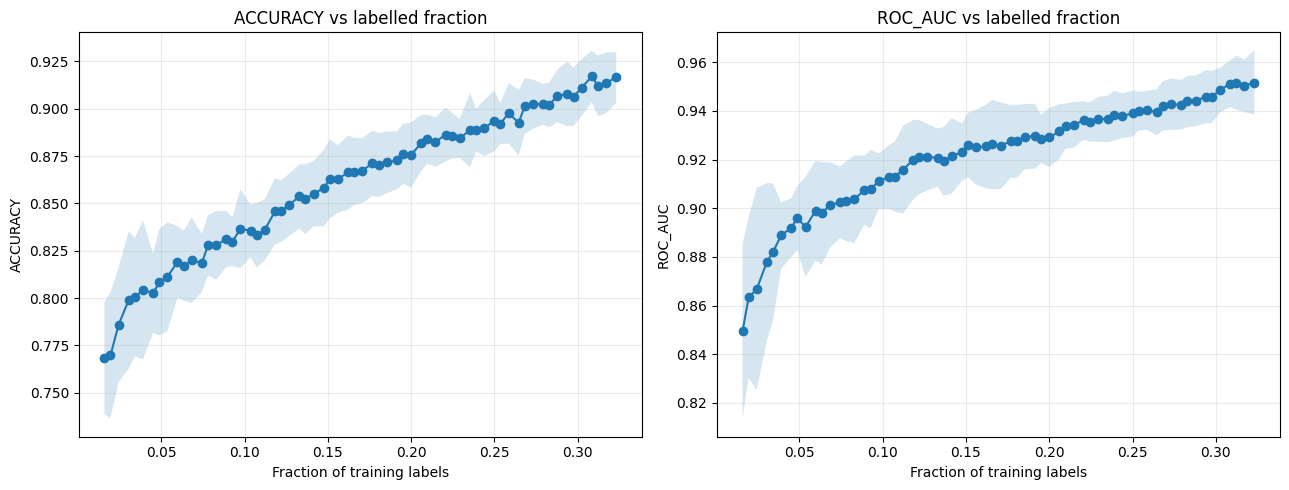

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
for ax, metric in zip(axes, ['accuracy','roc_auc']):
    g = histories.groupby('labelled_fraction')[metric].agg(['mean','std']).reset_index()
    ax.plot(g.labelled_fraction, g['mean'], marker='o')
    sd = g['std'].fillna(0)
    ax.fill_between(g.labelled_fraction, g['mean']-sd, g['mean']+sd, alpha=.18)
    ax.set(xlabel='Fraction of training labels', ylabel=metric.upper(),
           title=f'{metric.upper()} vs labelled fraction')
    ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## Confusion matrix and ROC curve for run 1

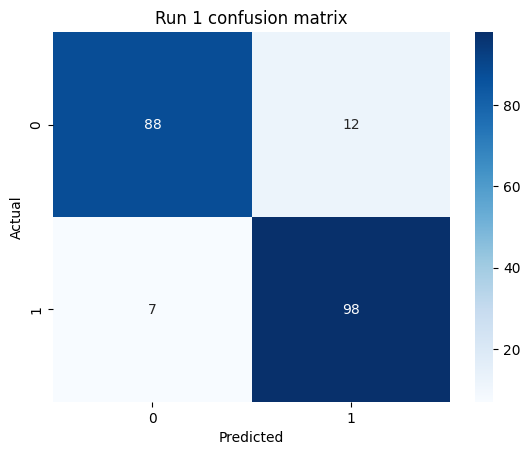

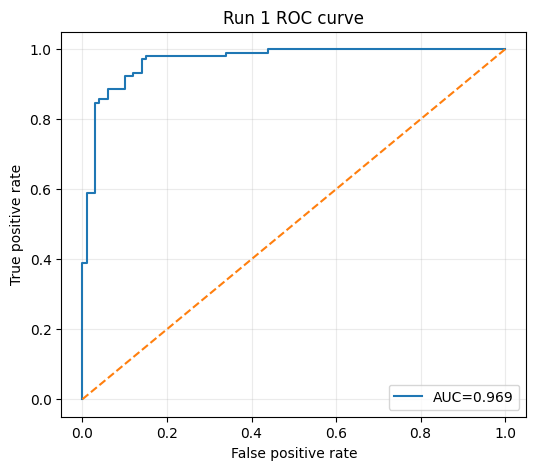

                   precision    recall  f1-score   support

 Absence/negative       0.93      0.88      0.90       100
Presence/positive       0.89      0.93      0.91       105

         accuracy                           0.91       205
        macro avg       0.91      0.91      0.91       205
     weighted avg       0.91      0.91      0.91       205



In [14]:

sample = run_outputs[0]

# Get the indices of the labelled training samples
final_ids = sample['output']['labelled_indices']

# Select rows by integer position using .iloc
X_final = sample['X_train'].iloc[final_ids]
y_final = sample['y_train'].iloc[final_ids]

# Train the final heterogeneous committee
final_models = fit_committee(
    X_final,
    y_final,
    sample['seed'] + 999
)

# Evaluate on the untouched test set
metrics_out, mean_prob, predictions = evaluate_committee(
    final_models,
    sample['X_test'],
    sample['y_test']
)

# Confusion matrix
sns.heatmap(
    confusion_matrix(sample['y_test'], predictions),
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Run 1 confusion matrix')
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(sample['y_test'], mean_prob)

plt.figure(figsize=(6, 5))
plt.plot(
    fpr, tpr,
    label=f"AUC={roc_auc_score(sample['y_test'], mean_prob):.3f}"
)
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Run 1 ROC curve')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# Classification report
print(
    classification_report(
        sample['y_test'],
        predictions,
        target_names=['Absence/negative', 'Presence/positive']
    )
)


## Save model and experiment metadata

In [15]:
import joblib
joblib.dump(final_models, ARTIFACT_DIR/'final_five_model_committee.joblib')
metadata = {
    'committee':['XGBoost','SVM_RBF','Random_Forest','Logistic_Regression','CatBoost'],
    'query_sizes':QUERY_SIZES, 'initial_label_fraction':INITIAL_LABEL_FRACTION,
    'label_budget_fraction':LABEL_BUDGET_FRACTION, 'test_size':TEST_SIZE,
    'n_runs':N_RUNS, 'positive_class':1, 'dataset':'Kaggle johnsmith88/heart-disease-dataset', 'source_file':str(DATA_PATH)
}
with open(ARTIFACT_DIR/'metadata.json','w') as f:
    json.dump(metadata,f,indent=2)
print('All artifacts saved in', ARTIFACT_DIR.resolve())

All artifacts saved in /kaggle/working/hcaal_v2_artifacts


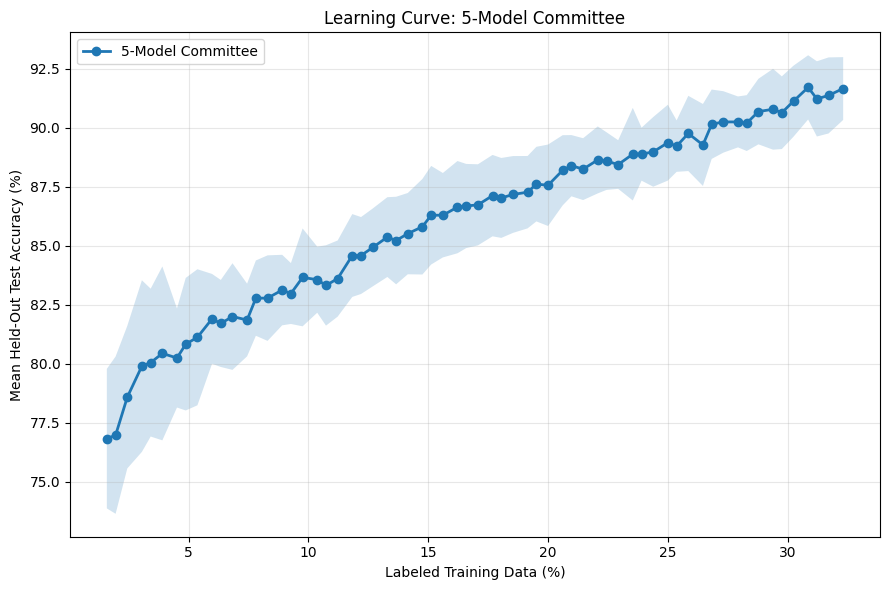

In [16]:
import matplotlib.pyplot as plt

# Calculate mean and standard deviation across 10 runs
curve = (
    histories.groupby("labelled_fraction")["accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

plt.figure(figsize=(9, 6))

plt.plot(
    curve["labelled_fraction"] * 100,
    curve["mean"] * 100,
    marker="o",
    linewidth=2,
    label="5-Model Committee"
)

plt.fill_between(
    curve["labelled_fraction"] * 100,
    (curve["mean"] - curve["std"]) * 100,
    (curve["mean"] + curve["std"]) * 100,
    alpha=0.2
)

plt.xlabel("Labeled Training Data (%)")
plt.ylabel("Mean Held-Out Test Accuracy (%)")
plt.title("Learning Curve: 5-Model Committee")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("learning_curve_5model.png", dpi=300)
plt.show()